1: Carga de Datos y Configuración Inicial

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fijar semilla para reproducibilidad
np.random.seed(42)

# Carga de datos original 
df = pd.read_csv('../../Datos/WA_Fn-UseC_-HR-Employee-Attrition.csv')

print(f"Dimensiones del dataset cargado: {df.shape}")

Dimensiones del dataset cargado: (1470, 35)


2: Test de Permutación para la Comparación de Ingresos según Salida (Attrition)

In [2]:
# Definición de grupos según la variable Attrition (Yes / No)
ingresos_si = df[df['Attrition'] == 'Yes']['MonthlyIncome'].values
ingresos_no = df[df['Attrition'] == 'No']['MonthlyIncome'].values

# Estadístico t de Welch original (diferencia de medias estandarizada por varianzas muestrales)
def welch_t_stat(x, y):
    mean_x, mean_y = np.mean(x), np.mean(y)
    var_x, var_y = np.var(x, ddof=1), np.var(y, ddof=1)
    n_x, n_y = len(x), len(y)
    
    # Recalculando el denominador del estadístico t de Welch en cada paso
    denominator = np.sqrt((var_x / n_x) + (var_y / n_y))
    if denominator == 0:
        return 0.0
    return (mean_x - mean_y) / denominator

t_obs = welch_t_stat(ingresos_si, ingresos_no)
print(f"Estadístico t de Welch observado: {t_obs:.4f}")

# Test de permutación (10,000 permutaciones)
n_permutaciones = 10000
combined = np.concatenate([ingresos_si, ingresos_no])
n_si = len(ingresos_si)

t_permutados = np.empty(n_permutaciones)

for i in range(n_permutaciones):
    np.random.shuffle(combined)
    perm_si = combined[:n_si]
    perm_no = combined[n_si:]
    t_permutados[i] = welch_t_stat(perm_si, perm_no)

# Cálculo del p-valor con corrección para evitar p = 0
# 
p_valor = (np.sum(np.abs(t_permutados) >= np.abs(t_obs)) + 1) / (n_permutaciones + 1)

print(f"P-valor ajustado (Permutaciones): {p_valor:.5f}")

Estadístico t de Welch observado: -7.4826
P-valor ajustado (Permutaciones): 0.00010


Intercambiabilidad y t de Welch:

Intercambiabilidad: La prueba de permutación exacta asume que, bajo la hipótesis nula, las etiquetas de los grupos (Attrition) son intercambiables para cada individuo. Esto significa que la distribución de los ingresos es exactamente idéntica en ambos grupos.

Rol de la Studentización: Al utilizar el estadístico t de Welch en lugar de una simple diferencia de medias, studentizamos el estadístico dividiéndolo por el error estándar estimado (que recalcula el denominador en cada permutación). Esto mitiga el impacto de tener varianzas diferentes entre los grupos comparados, mejorando la aproximación de la prueba, pero no elimina por completo los supuestos subyacentes (como la forma general de las distribuciones o la independencia de las observaciones).

3: Análisis Jackknife (Empleados Influyentes)

In [3]:
# Jackknife para identificar observaciones influyentes en la media general de ingreso y en la diferencia
n = len(df)
medias_jackknife = np.empty(n)
ingresos_totales = df['MonthlyIncome'].values

# Estimación Jackknife de la media global
media_global_orig = np.mean(ingresos_totales)

for i in range(n):
    # Dejar fuera el elemento i
    sample_i = np.delete(ingresos_totales, i)
    medias_jackknife[i] = np.mean(sample_i)

# Identificar puntos más influyentes (mayor distancia respecto a la media original)
df['jackknife_influence'] = np.abs(medias_jackknife - media_global_orig)
empleados_influyentes = df.sort_values(by='jackknife_influence', ascending=False).head(5)

print("Top 5 empleados con mayor influencia en la media de ingresos (Jackknife):")
print(empleados_influyentes[['EmployeeNumber', 'MonthlyIncome', 'Attrition', 'jackknife_influence']])

# Exportar tabla con empleados influyentes
tabla_influyentes = empleados_influyentes[['EmployeeNumber', 'MonthlyIncome', 'Attrition', 'jackknife_influence']]
tabla_influyentes.to_csv('../resultados/rodrigo_empleados_influyentes.csv', index=False)

Top 5 empleados con mayor influencia en la media de ingresos (Jackknife):
     EmployeeNumber  MonthlyIncome Attrition  jackknife_influence
190             259          19999        No             9.187249
746            1035          19973        No             9.169550
851            1191          19943        No             9.149128
165             226          19926        No             9.137555
568             787          19859       Yes             9.091946


4: Análisis de Sensibilidad a Ingresos Extremos (Valores Atípicos / Outliers)

In [4]:
# Definición de regla de sensibilidad (ej. método del Rango Intercuartílico - IQR para ingresos extremos)
Q1 = df['MonthlyIncome'].quantile(0.25)
Q3 = df['MonthlyIncome'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

# Análisis sin modificar el CSV original, creando una vista filtrada
df_sensibilidad = df[df['MonthlyIncome'] <= limite_superior].copy()

# Recalcular t de Welch sin outliers
ingresos_si_sens = df_sensibilidad[df_sensibilidad['Attrition'] == 'Yes']['MonthlyIncome'].values
ingresos_no_sens = df_sensibilidad[df_sensibilidad['Attrition'] == 'No']['MonthlyIncome'].values
t_sensibilidad = welch_t_stat(ingresos_si_sens, ingresos_no_sens)

print(f"Estadístico t original: {t_obs:.4f}")
print(f"Estadístico t tras remover extremos (> {limite_superior:.2f}): {t_sensibilidad:.4f}")

Estadístico t original: -7.4826
Estadístico t tras remover extremos (> 16581.00): -5.6945


5: Gráficos y Exportación

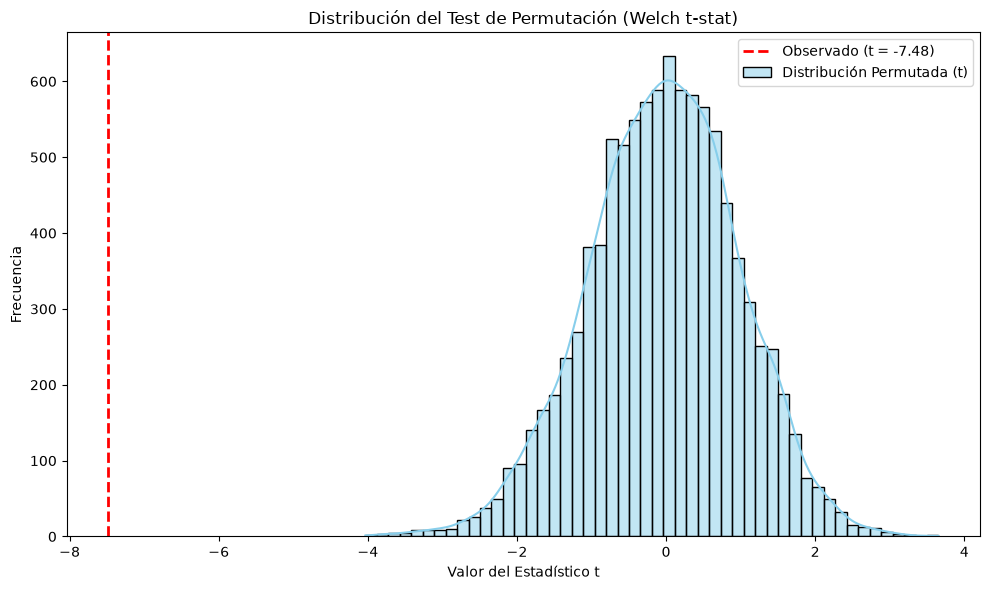

Archivos exportados correctamente.


In [5]:
# Gráfico de la distribución de permutaciones vs Estadístico observado
plt.figure(figsize=(10, 6))
sns.histplot(t_permutados, bins=50, kde=True, color='skyblue', label='Distribución Permutada (t)')
plt.axvline(t_obs, color='red', linestyle='--', linewidth=2, label=f'Observado (t = {t_obs:.2f})')
plt.title('Distribución del Test de Permutación (Welch t-stat)')
plt.xlabel('Valor del Estadístico t')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()

# Exportar gráfico 
plt.savefig('../resultados/rodrigo_permutacion_distribucion.png', dpi=300)
plt.show()

# Exportar resumen de resultados de sensibilidad en un DataFrame / CSV
resumen_sensibilidad = pd.DataFrame({
    'Metrica': ['t_observado_original', 'p_valor_permutacion', 't_sin_outliers', 'limite_iqr_superior'],
    'Valor': [t_obs, p_valor, t_sensibilidad, limite_superior]
})
resumen_sensibilidad.to_csv('../resultados/rodrigo_resumen_sensibilidad.csv', index=False)
print("Archivos exportados correctamente.")